# 02 · Predicting late deliveries at checkout

**Why this model:** notebook 01 showed that a late order is about 6.7x as likely to get a 1–2 star review.
If risky orders can be flagged **at the moment they are placed**, operations can act before the customer is disappointed:
upgrade the shipping option, nudge the seller to dispatch faster, or send a proactive message with a realistic date.

**Target:** `IsLate` = delivered after the estimated date shown at checkout (delivered orders only).

**Rule 1, no leakage:** only information known at purchase time is used. Delivery dates, carrier dates and the review all happen
*after* the purchase; using them would make the model look far better than it really is.

**Rule 2, time-based evaluation:** train on the past, choose the model on the next period, and report results on the most recent period,
exactly as the model would be used in production. A random split would leak future patterns into training.

| Period | Purchases | Used for |
|---|---|---|
| Train | Jan 2017 – Mar 2018 | fitting the models |
| Validation | Apr – May 2018 | choosing the model, early stopping, calibration |
| Test | Jun – Aug 2018 | final, untouched evaluation |

**Spoiler:** the obvious approach (a classifier trained on the late label) works on validation but **fails on the test period**,
because delivery promises were cut sharply in mid-2018. Diagnosing that and reframing the problem is the main lesson of this notebook.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, mean_absolute_error, roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import chart_style as cs

cs.apply_style()
warnings.filterwarnings("ignore", message=".*eval_set.*deprecated.*")  # newer LightGBM renamed the argument
SEED = 42
P = ROOT / "data" / "processed"

orders = pd.read_csv(P / "FactOrders.csv", parse_dates=["OrderDate", "DeliveredDate", "EstimatedDate"])
items = pd.read_csv(P / "FactOrderItems.csv")
products = pd.read_csv(P / "DimProduct.csv")
customers = pd.read_csv(P / "DimCustomer.csv")
sellers = pd.read_csv(P / "DimSeller.csv")

TRAIN_END, VALID_END, TEST_END = pd.Timestamp("2018-04-01"), pd.Timestamp("2018-06-01"), pd.Timestamp("2018-09-01")

## 1 · Feature engineering (purchase-time information only)

In [2]:
df = orders[orders["IsDelivered"] == 1].copy()

# Location
df = df.merge(customers[["CustomerKey", "State"]].rename(columns={"State": "CustomerState"}), on="CustomerKey", how="left")
df = df.merge(sellers[["SellerKey", "State"]].rename(columns={"State": "SellerState"}), on="SellerKey", how="left")
df["SameState"] = (df["CustomerState"] == df["SellerState"]).astype(int)

# Main product category = category of the most expensive item in the order
main_item = items.sort_values("Price").drop_duplicates("OrderKey", keep="last")[["OrderKey", "ProductKey"]]
main_item = main_item.merge(products[["ProductKey", "Category"]], on="ProductKey")
df = df.merge(main_item[["OrderKey", "Category"]].rename(columns={"Category": "MainCategory"}), on="OrderKey", how="left")

# Basket and calendar
df["FreightRatio"] = df["FreightValue"] / df["ProductValue"]
df["DayOfWeek"] = df["OrderDate"].dt.dayofweek
df["Month"] = df["OrderDate"].dt.month

# Platform load: orders placed in the 7 days before this order (captures Black Friday-style surges)
daily_orders = orders.groupby("OrderDate").size().asfreq("D", fill_value=0)
df["PlatformOrdersPrev7d"] = df["OrderDate"].map(daily_orders.rolling(7, min_periods=1).sum().shift(1).fillna(0))

# The estimate is a calendar date, so an order is late if it arrives on or after midnight of the day after the estimate.
# In "days since purchase" that cut-off is:
df["LateCutoffDays"] = df["PromisedDays"] + 1 - df["PurchaseHour"] / 24

### Seller track record without leakage
A seller's past late rate is a useful signal, but it may only count deliveries that had **already happened before the purchase date**.
`merge_asof` looks up, for every order, the seller's cumulative deliveries and late deliveries up to the day before the order.

In [3]:
seller_daily = (
    df.groupby(["SellerKey", "DeliveredDate"])["IsLate"].agg(Deliveries="size", Late="sum").reset_index()
    .sort_values(["SellerKey", "DeliveredDate"])
)
seller_daily[["CumDeliveries", "CumLate"]] = seller_daily.groupby("SellerKey")[["Deliveries", "Late"]].cumsum()

df = pd.merge_asof(
    df.sort_values("OrderDate"),
    seller_daily[["SellerKey", "DeliveredDate", "CumDeliveries", "CumLate"]].sort_values("DeliveredDate"),
    left_on="OrderDate", right_on="DeliveredDate", by="SellerKey",
    allow_exact_matches=False, suffixes=("", "_hist"),
).drop(columns="DeliveredDate_hist")
df[["CumDeliveries", "CumLate"]] = df[["CumDeliveries", "CumLate"]].fillna(0)

prior = df.loc[df["OrderDate"] < TRAIN_END, "IsLate"].mean()
SMOOTHING = 10  # sellers with few past deliveries are pulled towards the overall rate
df["SellerPriorDeliveries"] = df["CumDeliveries"]
df["SellerPriorLateRate"] = (df["CumLate"] + SMOOTHING * prior) / (df["CumDeliveries"] + SMOOTHING)

### Recent delivery speed (also leakage-free)
How long deliveries to the customer's state took **in the 30 days before the purchase**, and across the whole platform in the previous 14 days.
These features let the model adapt when logistics get faster or slower.

In [4]:
CALENDAR = pd.date_range("2017-01-01", "2018-10-31", freq="D")

def recent_delivery_days(frame: pd.DataFrame, by: str, window: int) -> pd.DataFrame:
    """Average delivery days of orders delivered in the `window` days before each date (that date excluded)."""
    daily = frame.groupby([by, "DeliveredDate"])["DeliveryDays"].agg(["sum", "size"])
    out = []
    for key, g in daily.groupby(level=0):
        g = g.droplevel(0).reindex(CALENDAR, fill_value=0)
        rolled = g.rolling(window, min_periods=1).sum().shift(1)
        out.append(pd.DataFrame({by: key, "OrderDate": CALENDAR, "value": (rolled["sum"] / rolled["size"]).values}))
    return pd.concat(out)

state_recent = recent_delivery_days(df, "CustomerState", 30).rename(columns={"value": "StateRecentDeliveryDays"})
df = df.merge(state_recent, on=["CustomerState", "OrderDate"], how="left")
platform_recent = recent_delivery_days(df.assign(All="all"), "All", 14).rename(columns={"value": "PlatformRecentDeliveryDays"})
df = df.merge(platform_recent.drop(columns="All"), on="OrderDate", how="left")

# Leakage check: recompute the history features for random orders by brute force
for _, r in df.sample(1000, random_state=SEED).iterrows():
    past = df[(df["SellerKey"] == r["SellerKey"]) & (df["DeliveredDate"] < r["OrderDate"])]
    assert len(past) == r["SellerPriorDeliveries"] and past["IsLate"].sum() == r["CumLate"]
    window = df[(df["CustomerState"] == r["CustomerState"]) & (df["DeliveredDate"] < r["OrderDate"])
                & (df["DeliveredDate"] >= r["OrderDate"] - pd.Timedelta(days=30))]
    assert (len(window) == 0 and np.isnan(r["StateRecentDeliveryDays"])) or np.isclose(window["DeliveryDays"].mean(), r["StateRecentDeliveryDays"])
print("Leakage checks passed on 1,000 random orders")

Leakage checks passed on 1,000 random orders


In [5]:
NUMERIC = [
    "PromisedDays", "DistanceKm", "ItemCount", "SellerCount", "ProductValue", "FreightValue", "FreightRatio",
    "TotalWeightG", "Installments", "PurchaseHour", "DayOfWeek", "Month", "SameState",
    "PlatformOrdersPrev7d", "SellerPriorDeliveries", "SellerPriorLateRate",
    "StateRecentDeliveryDays", "PlatformRecentDeliveryDays",
]
CATEGORICAL = ["CustomerState", "SellerState", "MainCategory", "PaymentType"]
for c in CATEGORICAL:
    df[c] = pd.Categorical(df[c].fillna("Unknown"))
df["IsLate"] = df["IsLate"].astype(int)
df = df.sort_values("OrderKey").reset_index(drop=True)

train = df[df["OrderDate"] < TRAIN_END]
valid = df[(df["OrderDate"] >= TRAIN_END) & (df["OrderDate"] < VALID_END)]
test = df[(df["OrderDate"] >= VALID_END) & (df["OrderDate"] < TEST_END)]
y_train, y_valid, y_test = (s["IsLate"].to_numpy() for s in (train, valid, test))
pd.DataFrame(
    {"Orders": [len(s) for s in (train, valid, test)], "Late rate": [f"{s['IsLate'].mean():.1%}" for s in (train, valid, test)]},
    index=["Train (Jan 2017 - Mar 2018)", "Validation (Apr - May 2018)", "Test (Jun - Aug 2018)"],
)

,Orders,Late rate
Train (Jan 2017 - Mar 2018),64053,8.0%
Validation (Apr - May 2018),13547,5.5%
Test (Jun - Aug 2018),18603,3.6%


With 4–8% positives, a model that always predicts "on time" is over 90% accurate and completely useless,
so the models are compared with **ranking metrics**: ROC-AUC, PR-AUC and the share of late orders caught in the riskiest 10%.

In [6]:
def evaluate(y_true: np.ndarray, scores: np.ndarray, top_share: float = 0.10) -> dict:
    ranked = y_true[np.argsort(-scores)]
    n_top = int(len(scores) * top_share)
    caught = ranked[:n_top].sum() / y_true.sum()
    return {
        "ROC-AUC": roc_auc_score(y_true, scores),
        "PR-AUC": average_precision_score(y_true, scores),
        "Late orders caught in top 10%": caught,
        "Lift in top 10%": caught / top_share,
    }

LGB_BASE = dict(learning_rate=0.03, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
                colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED, verbose=-1, n_jobs=4)
valid_scores, test_scores = {}, {}

## 2 · Attempt 1: a classifier on the late label

In [7]:
clf = lgb.LGBMClassifier(n_estimators=3000, objective="binary", **LGB_BASE)
clf.fit(train[NUMERIC + CATEGORICAL], y_train, eval_set=[(valid[NUMERIC + CATEGORICAL], y_valid)], eval_metric="auc",
        callbacks=[lgb.early_stopping(200, verbose=False)])
valid_scores["Direct classifier"] = clf.predict_proba(valid[NUMERIC + CATEGORICAL])[:, 1]
test_scores["Direct classifier"] = clf.predict_proba(test[NUMERIC + CATEGORICAL])[:, 1]
print(f"Validation ROC-AUC {roc_auc_score(y_valid, valid_scores['Direct classifier']):.3f}   "
      f"Test ROC-AUC {roc_auc_score(y_test, test_scores['Direct classifier']):.3f}")

Validation ROC-AUC 0.699   Test ROC-AUC 0.466


Reasonable on validation, close to a coin flip on test. Something changed between the periods.

### Diagnosis: delivery promises were cut sharply in mid-2018

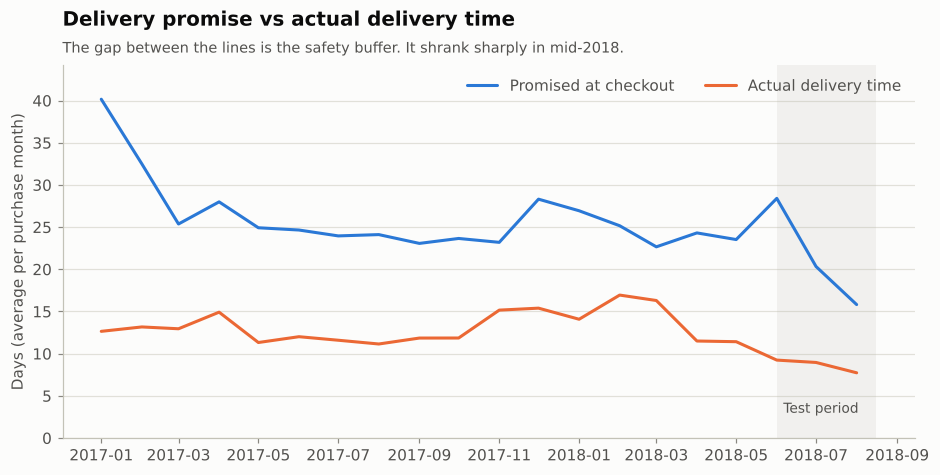

In [8]:
by_month = df.groupby(df["OrderDate"].dt.to_period("M")).agg(
    Promised=("PromisedDays", "mean"), Actual=("DeliveryDays", "mean"), LateRate=("IsLate", "mean"))
by_month.index = by_month.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(by_month.index, by_month["Promised"], color=cs.BLUE, label="Promised at checkout")
ax.plot(by_month.index, by_month["Actual"], color=cs.ORANGE, label="Actual delivery time")
ax.axvspan(VALID_END, by_month.index.max() + pd.Timedelta(days=15), color=cs.GRAY, alpha=0.15, linewidth=0)
ax.text(VALID_END + pd.Timedelta(days=5), 3, "Test period", color=cs.INK_SECONDARY, fontsize=9)
ax.set_ylim(0, by_month["Promised"].max() * 1.1)
ax.set_ylabel("Days (average per purchase month)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncols=2)
ax.set_title("Delivery promise vs actual delivery time")
cs.subtitle(ax, "The gap between the lines is the safety buffer. It shrank sharply in mid-2018.")
cs.save(fig, "06_promise_vs_actual.png")
plt.show()

In [9]:
def single_feature_auc(frame: pd.DataFrame, feature: str) -> float:
    x = frame[feature].fillna(frame[feature].median())
    return roc_auc_score(frame["IsLate"], x)

pd.DataFrame(
    {name: {f: single_feature_auc(s, f) for f in ["DistanceKm", "SameState", "FreightValue", "PromisedDays"]}
     for name, s in [("Train", train), ("Validation", valid), ("Test", test)]}
).style.format("{:.2f}").background_gradient(cmap="RdBu", vmin=0.3, vmax=0.7, axis=None)

,Train,Validation,Test
DistanceKm,0.59,0.65,0.40
SameState,0.42,0.40,0.60
FreightValue,0.59,0.59,0.42
PromisedDays,0.49,0.45,0.26


Reading the table: an AUC above 0.5 means "higher value = more likely late"; below 0.5 means the opposite.
The average promise fell from about 24 days (Apr–May 2018) to 16 days (Aug 2018), which looks like a change in how Olist set its estimates.
Before the change, **long distance** meant risk. In the test period the relationship **flips**: with tighter promises,
short and same-state deliveries are now the ones most often late. The classifier memorised the old relationships,
so it fails. This is **concept drift**, most likely caused by a change in how delivery estimates were set, and no amount of hyper-parameter tuning fixes it.

## 3 · Attempt 2: model what is stable, then compare it with the promise

How long a delivery takes depends on physics and logistics (distance, weight, seller, recent speed to that region).
Whether it counts as *late* also depends on a promise policy that the business can change at any time.
So the problem is split in two:

1. **Stage 1:** a LightGBM regression predicts delivery time (log days) **without** using the promise.
2. **Stage 2:** the risk score compares the predicted delivery time with the late cut-off. A logistic regression fitted on the validation
   period turns that gap into a 0–1 score.

Baseline to beat, a **rule of thumb**: `promised days − recent average delivery days to the customer's state`. A small buffer means high risk.

In [10]:
STAGE1_FEATURES = [f for f in NUMERIC if f != "PromisedDays"] + CATEGORICAL
reg = lgb.LGBMRegressor(n_estimators=5000, objective="regression", **LGB_BASE)
reg.fit(train[STAGE1_FEATURES], np.log(train["DeliveryDays"].clip(lower=0.5)),
        eval_set=[(valid[STAGE1_FEATURES], np.log(valid["DeliveryDays"].clip(lower=0.5)))],
        callbacks=[lgb.early_stopping(200, verbose=False)])

def predicted_days(frame: pd.DataFrame) -> np.ndarray:
    return np.exp(reg.predict(frame[STAGE1_FEATURES]))

def gap(frame: pd.DataFrame) -> np.ndarray:
    """Log of predicted delivery days over the late cut-off. Above 0 = expected to arrive late."""
    return np.log(predicted_days(frame)) - np.log(frame["LateCutoffDays"].to_numpy())

naive_mae = mean_absolute_error(test["DeliveryDays"], np.full(len(test), train["DeliveryDays"].median()))
print(f"Stage 1 ({reg.best_iteration_} trees) - test MAE: {mean_absolute_error(test['DeliveryDays'], predicted_days(test)):.2f} days "
      f"(predicting the training median: {naive_mae:.2f} days)")

calibrator = LogisticRegression().fit(gap(valid).reshape(-1, 1), y_valid)
for name, frame, store in [("valid", valid, valid_scores), ("test", test, test_scores)]:
    store["Two-stage model"] = calibrator.predict_proba(gap(frame).reshape(-1, 1))[:, 1]
    store["Rule of thumb"] = -(frame["PromisedDays"] - frame["StateRecentDeliveryDays"].fillna(frame["StateRecentDeliveryDays"].median())).to_numpy()

Stage 1 (101 trees) - test MAE: 4.83 days (predicting the training median: 5.19 days)


## 4 · Results

In [11]:
order = ["Direct classifier", "Rule of thumb", "Two-stage model"]
comparison = pd.concat(
    {
        "Validation (model selection)": pd.DataFrame({m: evaluate(y_valid, valid_scores[m]) for m in order}).T,
        "Test (final)": pd.DataFrame({m: evaluate(y_test, test_scores[m]) for m in order}).T,
    },
    axis=1,
)
comparison.style.format("{:.3f}").format("{:.1%}", subset=[c for c in comparison.columns if "caught" in c[1]]).format(
    "{:.1f}x", subset=[c for c in comparison.columns if "Lift" in c[1]])

**Model selection uses validation only.** The two-stage model wins there, so it is the one carried forward.

On the test period it keeps working (ROC-AUC 0.74; the riskiest 10% of orders contain about 35% of all late orders, a 3.5x lift),
while the direct classifier collapses. The simple rule of thumb actually scores slightly *higher* on test, although it was clearly worse on validation.
Both approaches survive the change in promises for the same reason: they compare the promise against **recent** delivery speed instead of memorising old patterns.

Honest conclusion: in production, ship the two-stage model, keep the rule of thumb as a benchmark, and re-check both every month.

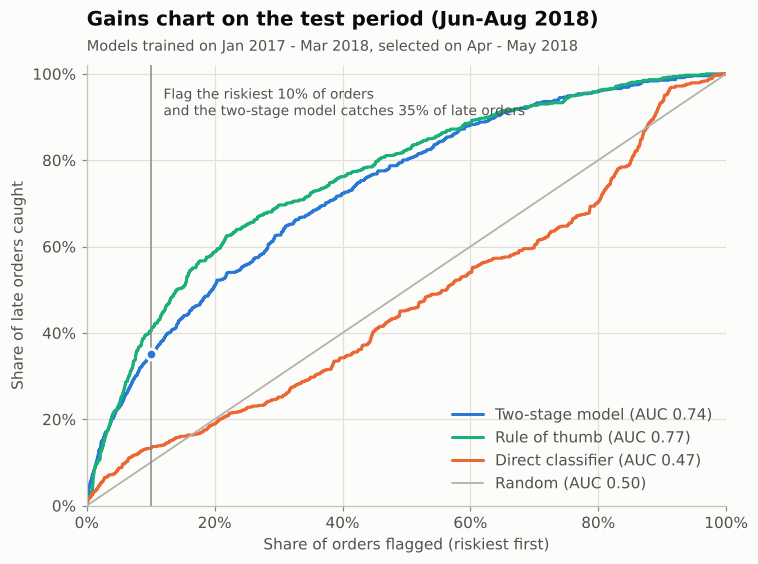

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
share = np.arange(1, len(y_test) + 1) / len(y_test)
styles = {"Two-stage model": cs.BLUE, "Rule of thumb": cs.AQUA, "Direct classifier": cs.ORANGE}
for name, color in styles.items():
    caught = np.cumsum(y_test[np.argsort(-test_scores[name])]) / y_test.sum()
    ax.plot(share, caught, color=color, label=f"{name} (AUC {roc_auc_score(y_test, test_scores[name]):.2f})")
ax.plot([0, 1], [0, 1], color=cs.GRAY, linewidth=1.2, label="Random (AUC 0.50)")
cap10 = evaluate(y_test, test_scores["Two-stage model"])["Late orders caught in top 10%"]
ax.axvline(0.10, color=cs.INK_MUTED, linewidth=1)
ax.plot([0.10], [cap10], marker="o", markersize=7, color=cs.BLUE, markeredgecolor=cs.SURFACE, markeredgewidth=2, zorder=5)
ax.text(0.12, 0.97, f"Flag the riskiest 10% of orders\nand the two-stage model catches {cap10:.0%} of late orders",
        color=cs.INK_SECONDARY, fontsize=9, va="top")
ax.xaxis.set_major_formatter(cs.pct())
ax.yaxis.set_major_formatter(cs.pct())
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Share of orders flagged (riskiest first)")
ax.set_ylabel("Share of late orders caught")
ax.legend(loc="lower right")
ax.set_title("Gains chart on the test period (Jun-Aug 2018)")
cs.subtitle(ax, "Models trained on Jan 2017 - Mar 2018, selected on Apr - May 2018")
cs.save(fig, "07_model_gains_chart.png")
plt.show()

### What drives the delivery-time prediction?
Permutation importance on the test period: how much the error grows when one feature is shuffled.
Unlike LightGBM's built-in "gain" importance, it is measured on unseen data and is not biased towards high-cardinality features.

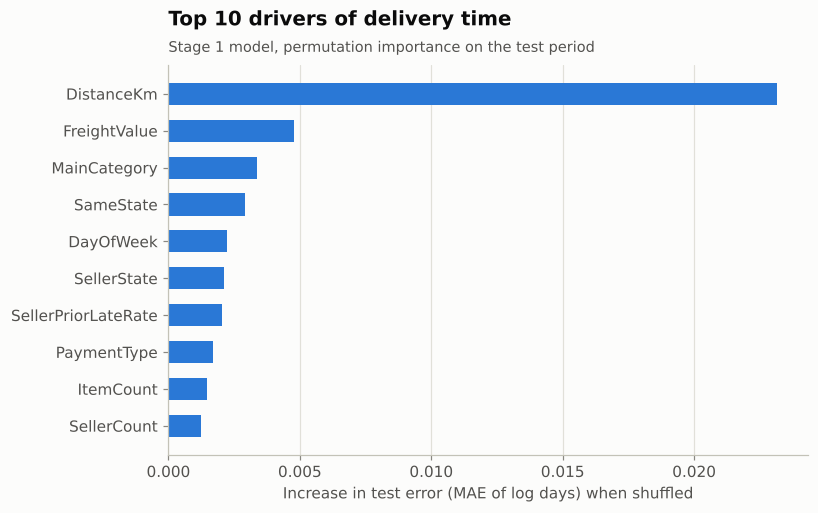

DistanceKm                    0.0232
FreightValue                  0.0048
MainCategory                  0.0034
SameState                     0.0029
DayOfWeek                     0.0022
SellerState                   0.0021
SellerPriorLateRate           0.0020
PaymentType                   0.0017
ItemCount                     0.0015
SellerCount                   0.0012
SellerPriorDeliveries         0.0006
TotalWeightG                  0.0004
ProductValue                  0.0001
FreightRatio                  0.0000
PurchaseHour                  0.0000
PlatformRecentDeliveryDays    0.0000
Installments                  0.0000
Month                        -0.0001
PlatformOrdersPrev7d         -0.0023
StateRecentDeliveryDays      -0.0034
CustomerState                -0.0051
dtype: float64

In [13]:
perm = permutation_importance(reg, test[STAGE1_FEATURES], np.log(test["DeliveryDays"].clip(lower=0.5)),
                              scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED, n_jobs=1)
importance = pd.Series(perm.importances_mean, index=STAGE1_FEATURES).sort_values(ascending=False)
top = importance.head(10)[::-1]

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(top.index, top.values, height=0.6, color=cs.BLUE)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Increase in test error (MAE of log days) when shuffled")
ax.set_title("Top 10 drivers of delivery time")
cs.subtitle(ax, "Stage 1 model, permutation importance on the test period")
cs.save(fig, "08_feature_importance.png")
plt.show()
importance.round(4)

### Calibration
The score is calibrated on the validation period (5.5% late), but the test period had only 3.6% late orders, so the scores run high.
The **ranking** is what operations use ("check the riskiest 10% today"); the score should not be shown to customers as a probability
without recalibrating on the most recent weeks.

In [14]:
print(f"Average score on test: {test_scores['Two-stage model'].mean():.1%}   Actual late rate on test: {y_test.mean():.1%}")

Average score on test: 9.2%   Actual late rate on test: 3.6%


## 5 · Business scenario
**Assumption (not measured in this data):** an intervention on a flagged order (expedite, or a proactive message with a revised date)
prevents the bad review on some share of the flagged late orders. The table shows the effect for different success rates,
using the bad-review rates from notebook 01 (62.4% for late orders vs 9.2% for on-time orders).

In [15]:
n_flagged = int(len(test) * 0.10)
late_caught = int(y_test[np.argsort(-test_scores["Two-stage model"])[:n_flagged]].sum())
scenario = pd.DataFrame({"Intervention success rate": [0.25, 0.50, 0.75]})
scenario["Late orders turned on-time"] = (late_caught * scenario["Intervention success rate"]).round().astype(int)
scenario["Bad reviews avoided"] = (scenario["Late orders turned on-time"] * (0.624 - 0.092)).round().astype(int)
print(f"Test period: {len(test):,} delivered orders, {int(y_test.sum()):,} late. "
      f"Flagging the riskiest {n_flagged:,} orders (10%) catches {late_caught:,} of them.")
scenario

Test period: 18,603 delivered orders, 672 late. Flagging the riskiest 1,860 orders (10%) catches 236 of them.


,Intervention success rate,Late orders turned on-time,Bad reviews avoided
0,0.25,59,31
1,0.50,118,63
2,0.75,177,94


## 6 · Export scores for the Power BI "Delivery risk" page

In [16]:
out = test[["OrderKey", "OrderDate", "CustomerKey", "SellerKey", "IsLate"]].copy()
out["PredictedDeliveryDays"] = predicted_days(test).round(1)
out["LateRiskScore"] = test_scores["Two-stage model"].round(4)
out["RiskDecile"] = pd.qcut(out["LateRiskScore"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)
out["RiskBand"] = np.select([out["RiskDecile"] == 1, out["RiskDecile"] <= 3], ["High", "Medium"], default="Low")
out["RiskBandSort"] = out["RiskBand"].map({"High": 1, "Medium": 2, "Low": 3})
out = out.rename(columns={"IsLate": "ActualLate"})[
    ["OrderKey", "OrderDate", "CustomerKey", "SellerKey", "PredictedDeliveryDays", "LateRiskScore",
     "RiskDecile", "RiskBand", "RiskBandSort", "ActualLate"]
]
out.to_csv(P / "FactLateRiskScores.csv", index=False, date_format="%Y-%m-%d", encoding="utf-8-sig")

summary = {
    "periods": {"train": "2017-01-01 to 2018-03-31", "validation": "2018-04-01 to 2018-05-31", "test": "2018-06-01 to 2018-08-31"},
    "test_orders": int(len(test)),
    "test_late_orders": int(y_test.sum()),
    "test_late_rate": round(float(y_test.mean()), 4),
    "validation": {m: {k: round(float(v), 4) for k, v in evaluate(y_valid, valid_scores[m]).items()} for m in order},
    "test": {m: {k: round(float(v), 4) for k, v in evaluate(y_test, test_scores[m]).items()} for m in order},
    "stage1_trees": int(reg.best_iteration_),
    "stage1_test_mae_days": round(float(mean_absolute_error(test["DeliveryDays"], predicted_days(test))), 2),
    "naive_test_mae_days": round(float(naive_mae), 2),
    "top_delivery_time_drivers": list(importance.head(5).index),
    "flagged_top10_orders": n_flagged,
    "flagged_top10_late_caught": late_caught,
}
(ROOT / "docs" / "model_metrics.json").write_text(json.dumps(summary, indent=2))
out.groupby(["RiskBandSort", "RiskBand"]).agg(Orders=("OrderKey", "size"), ActualLateRate=("ActualLate", "mean"))

,,Orders,ActualLateRate
RiskBandSort,RiskBand,,
1,High,1861,0.126814
2,Medium,3720,0.049731
3,Low,13022,0.019275


## Limitations and next steps
- **Label timing:** orders placed at the very end of August 2018 that were still in transit when the data was extracted are missing, which can slightly understate the late rate in the last weeks.
- **Drift:** late rates swing from 1% to 19% by month, and the delivery promises changed. Retrain and recalibrate monthly; track the capture rate of the riskiest 10%.
- **Missing signals:** carrier, shipping method and real-time tracking events are not in the dataset and would likely improve stage 1.
- **Causality:** the model finds *who* is at risk, not *what fixes it*. An A/B test of the intervention is needed to measure the real impact.
- **Better promises:** stage 1 could also be used the other way round, to set a more accurate delivery estimate at checkout.